# Рекомендательная система книг: полный анализ данных и построение моделей

**Задача проекта.** Пользователь выбирает книгу в веб-приложении и получает список похожих книг. Рекомендации строятся по трём признакам: **жанр, описание и количество страниц**.

**Тип системы.** Content-based (по содержимому) — в датасете нет истории чтения пользователей, поэтому сравниваются сами книги друг с другом, а не "похожие читатели".

**Данные.** `Books.xlsx` — 2049 книг, 11 колонок: `title`, `author`, `pages`, `genre`, `description`, `published_date`, `publisher`, `language`, `average_rating`, `ratings_count`, `thumbnail`.

## Оглавление

- **Глава 1. Импорт и очистка данных** — библиотеки, загрузка файла, пропуски
- **Глава 2. Разведочный анализ (EDA)** — выбросы, дубликаты, жанры, тренды чтения, рейтинг, год издания, язык
- **Глава 3. Модели рекомендаций** — TF-IDF (Модель A), жанр+страницы (Модель B), гибрид, сравнение, объяснимость
- **Глава 4. Кластеризация** — KMeans, метод локтя, PCA, интерпретация
- **Глава 5. Целевая переменная** — предсказание рейтинга (Linear Regression, Random Forest), важность признаков, SHAP
- **Глава 6. Матрица корреляции** — связь между страницами, рейтингом и числом оценок
- **Глава 7. Модель C** — похожесть по жанру и рейтингу
- **Глава 8. Итоги**

Графики сохраняются в `frontend/charts/`; часть из них выводится на сайте во вкладке «Дашборд». Финальная модель переносится в `backend/model.py` и используется AI-агентом (Groq).

# Глава 1. Импорт и очистка данных

## 1.1 Импорт библиотек

**Нужно для:** подключения всех инструментов, которые понадобятся по ходу всего ноутбука — от чтения Excel-файла до построения моделей и графиков. Собраны в одном месте, чтобы не искать импорты по всему файлу.

In [1]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import matplotlib.pyplot as plt
import seaborn as sns
import random


**Вывод:** каждая библиотека нужна для своей части проекта:
- `pandas`, `numpy` — чтение и обработка таблиц, числовые массивы;
- `TfidfVectorizer` — превращает текст описаний в числа (Модель A);
- `MinMaxScaler` — приводит числовые признаки к диапазону 0–1 (Модель B);
- `cosine_similarity` — считает, насколько две книги похожи друг на друга;
- `KMeans`, `PCA` — кластеризация книг и визуализация результата в 2D;
- `train_test_split`, `LinearRegression`, `RandomForestRegressor`, метрики — для задачи предсказания рейтинга (глава 5);
- `matplotlib`, `seaborn` — построение графиков;
- `random` — случайная, но воспроизводимая выборка книг при оценке моделей.

---

## 1.2 Загрузка данных

**Нужно для:** чтения файла `Books.xlsx` в таблицу `df` (pandas DataFrame), с которой дальше работает весь ноутбук.

In [2]:
df = pd.read_excel("../data/Books.xlsx")

print("Загружено книг:", len(df))
df.head()


Загружено книг: 2049


,title,author,pages,genre,description,published_date,publisher,language,average_rating,ratings_count,thumbnail
0,Fictional Points of View,Peter Lamarque,252.0,Literary Criticism,The volume focuses on a wide range of thinkers...,1996,Cornell University Press,en,5.0,250000,http://books.google.com/books/content?id=rh-om...
1,Science Fiction and Fantasy Literature,"R. Reginald, Douglas Menville, Mary A. Burgess",802.0,Reference,"Science Fiction and Fantasy Literature, A Chec...",2010-09-01,Wildside Press LLC,en,7.0,1000000,http://books.google.com/books/content?id=P8zW2...
2,Library of Congress Subject Headings,Library of Congress. Cataloging Policy and Sup...,1662.0,"Subject headings, Library of Congress",No description available,2004,Unknown Publisher,en,3.0,150000,http://books.google.com/books/content?id=pEhkh...
3,Library of Congress Subject Headings,Library of Congress,1512.0,"Subject headings, Library of Congress",No description available,2007,Unknown Publisher,en,4.0,200000,http://books.google.com/books/content?id=FgAjF...
4,Fictional Space in the Modernist and Post-mode...,Carl Darryl Malmgren,248.0,Fiction,Fictional space is the imaginal expanse of fie...,1985,Bucknell University Press,en,1.0,300000,http://books.google.com/books/content?id=KXzoz...


**Вывод:** загружено **2049 книг**. В выводе видно, что у части книг стоят заглушки (`Unknown Author`, `Unknown Publisher`, `Unknown Genre`, `No description available`) — это пропуски, записанные текстом, а не пустой ячейкой, поэтому их нужно находить и обрабатывать отдельно (раздел 1.3).

*Замечание о качестве данных:* в некоторых строках встречаются испорченные символы кодировки (например, «BrontГ«» вместо «Brontë»). На расчёты это не влияет, но на сайте такие названия отображаются как есть.

---

## 1.3 Очистка данных

**Нужно для:**
- **Пропуски в `pages`** (у 3 книг не указано количество страниц) — заполняем **медианой**. Медиана устойчивее среднего к выбросам (среднее 411.8 «тянется» за редкими супер-толстыми книгами, медиана 289.5 — нет).
- **Признак `has_description`** — флаг, есть ли у книги реальное описание. Нужен, потому что отсутствие описания в датасете не `NaN`, а текст-заглушка `"No description available"`, который обычная проверка на пропуски не находит.

In [3]:
df['pages'] = df['pages'].fillna(df['pages'].median())
df['has_description'] = df['description'] != 'No description available'

print("Пропуски после очистки:")
print(df.isna().sum())
print("\nКниг без описания:", (~df['has_description']).sum())


Пропуски после очистки:
title              0
author             0
pages              0
genre              0
description        0
published_date     0
publisher          0
language           0
average_rating     0
ratings_count      0
thumbnail          0
has_description    0
dtype: int64

Книг без описания: 506


**Вывод:** пропусков в таблице не осталось. **506 книг (≈25%) — без реального описания.** Это важная цифра: по тексту такие книги сравнивать нельзя, значит нужна вторая модель, не зависящая от текста (см. Модель B, глава 3).

# Глава 2. Разведочный анализ данных (EDA)

Цель — понять, что за данные перед нами, и найти проблемы, которые повлияют на модели: **выбросы, дубликаты, перекос жанров**, а также посмотреть на **тренды чтения** (популярность, рейтинг, год издания, язык).

## 2.1 Статистика по количеству страниц

**Нужно для:** первой оценки, есть ли в данных аномальные значения.

In [4]:
print(df['pages'].describe())
print("\nТоп-10 книг по количеству страниц:")
print(df.nlargest(10, 'pages')[['title', 'pages', 'genre']])


count    2049.000000
mean      411.830405
std       446.500411
min         8.000000
25%       174.000000
50%       289.500000
75%       496.000000
max      8114.000000
Name: pages, dtype: float64

Топ-10 книг по количеству страниц:
                                                  title   pages  \
763   The Complete Works of Arthur Conan Doyle (Illu...  8114.0   
1513  Complete Works of C.S. Lewis - The Chronicles ...  5494.0   
761   The Complete Short Stories of Sir Arthur Conan...  3907.0   
1088                e-Pedia: Game of Thrones (season 6)  3682.0   
516       Drafting Technology Patent License Agreements  3347.0   
1611                     Box Digital вЂ“ Robert Langdon  3219.0   
1737             The Complete Novels of BrontГ« Sisters  3101.0   
1912  Artificial Intelligence: Concepts, Methodologi...  3095.0   
118   Universal Pronouncing Dictionary of Biography ...  2936.0   
219                        Handbook of Medieval Studies  2822.0   

                   genre  
763

**Вывод:** медиана — **289.5** стр., среднее — **411.8** стр. (среднее заметно больше медианы — признак «хвоста» из больших значений). Максимум — **8114** стр., это в 28 раз больше медианы. В топ-10 — сборники сочинений и энциклопедии («Complete Works of Arthur Conan Doyle» и т.п.) — то есть реальные, но нетипичные книги, которые нельзя просто удалить.

---

## 2.2 Ограничение выбросов (capping)

**Нужно для:** проверки перцентилей и обрезки экстремальных значений `pages`, чтобы они не искажали расчёт сходства и нормализацию. Метод — **capping по 99-му перцентилю**: значения выше порога заменяются самим порогом, записи не удаляются.

In [5]:
print("95-й перцентиль:", df['pages'].quantile(0.95))
print("99-й перцентиль:", df['pages'].quantile(0.99))

cap = df['pages'].quantile(0.99)
df['pages_capped'] = df['pages'].clip(upper=cap)

print("\nПосле capping:")
print(df['pages_capped'].describe())


95-й перцентиль: 1167.1999999999998
99-й перцентиль: 1989.12

После capping:
count    2049.000000
mean      400.800400
std       364.269153
min         8.000000
25%       174.000000
50%       289.500000
75%       496.000000
max      1989.120000
Name: pages_capped, dtype: float64


**Вывод:** 95-й перцентиль — 1167 стр. (обрезал бы слишком много, ~5% книг), 99-й — 1989 стр. (затрагивает только самые экстремальные ~1%). После capping максимум упал с 8114 до **1989.12**, при этом медиана и квартили (174 / 289.5 / 496) не изменились — обычные книги не затронуты.

---

## 2.3 График: выбросы до и после (boxplot)

**Нужно для:** наглядной визуализации эффекта capping.

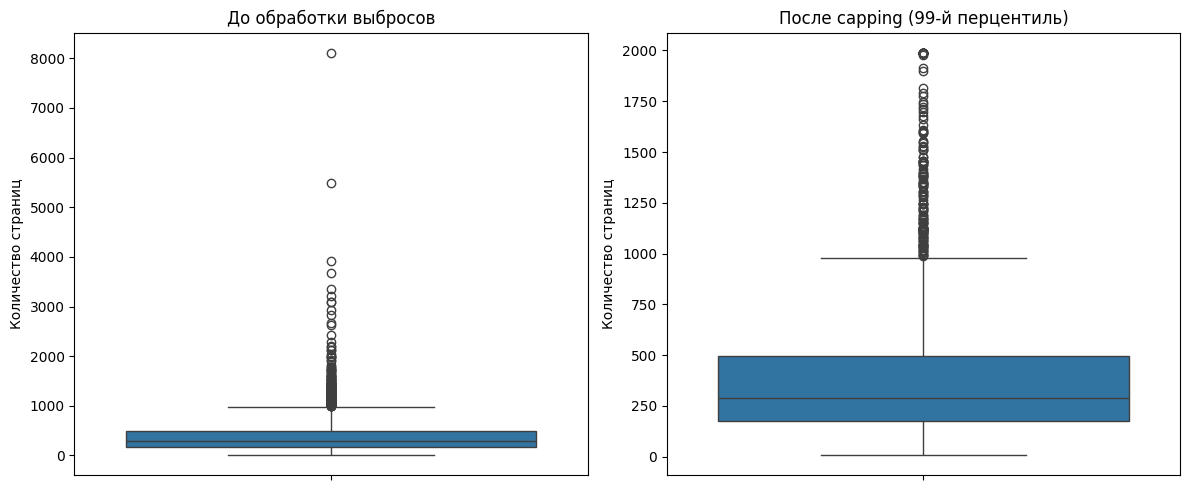

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['pages'], ax=axes[0])
axes[0].set_title('До обработки выбросов')
axes[0].set_ylabel('Количество страниц')

sns.boxplot(y=df['pages_capped'], ax=axes[1])
axes[1].set_title('После capping (99-й перцентиль)')
axes[1].set_ylabel('Количество страниц')

plt.tight_layout()
plt.savefig('../../frontend/charts/outliers.png', dpi=100)
plt.show()


**Вывод:** слева «коробка» почти не видна — прижата к низу из-за выбросов, уходящих выше 8000. Справа коробка хорошо читается: типичная книга — 174–496 страниц. Capping не убирает «толстые» книги, а лишь не даёт нескольким экстремальным значениям определять масштаб для остальных. График сохранён в `frontend/charts/outliers.png`.

---

## 2.4 Анализ дубликатов — повторяющиеся названия

**Нужно для:** проверки, что означают 149 повторов `title` — одна ли это книга или разные. Строим столбчатые диаграммы для 6 самых частых названий: ось X — жанр каждой записи, ось Y — число страниц.

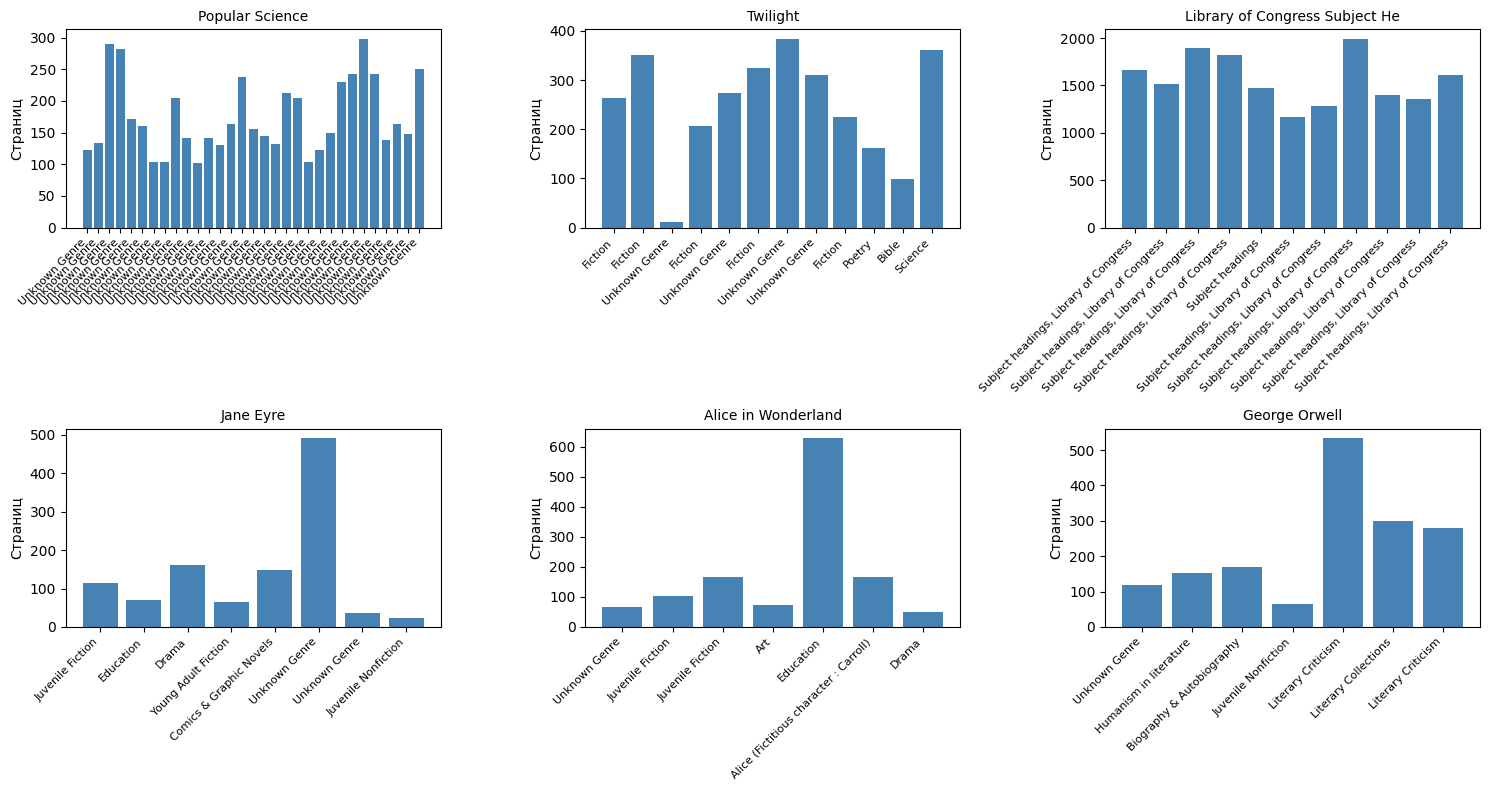

In [7]:
dup_titles = df[df['title'].duplicated(keep=False)]
top_dup_names = dup_titles['title'].value_counts().head(6).index

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, title in enumerate(top_dup_names):
    subset = df[df['title'] == title]
    axes[i].bar(range(len(subset)), subset['pages'], color='steelblue')
    axes[i].set_xticks(range(len(subset)))
    axes[i].set_xticklabels(subset['genre'], rotation=45, ha='right', fontsize=8)
    axes[i].set_title(title[:30], fontsize=10)
    axes[i].set_ylabel('Страниц')

plt.tight_layout()
plt.savefig('../../frontend/charts/duplicates.png', dpi=100)
plt.show()


**Вывод:** записи с одним и тем же названием сильно различаются по жанру и объёму. Например, «Jane Eyre» — от ~20 до ~500 стр., разные жанры (Juvenile Fiction, Drama, Comics & Graphic Novels) — это сокращённые, детские, драматические версии и полные издания. «Popular Science», «Library of Congress Subject Headings» — периодические издания с множеством выпусков под одним названием.

**Главный вывод: название (`title`) не является уникальным идентификатором книги.** Удалять записи по совпадению `title` нельзя — так мы бы потеряли реальные, разные книги. График сохранён в `frontend/charts/duplicates.png`.

---

## 2.5 Удаление настоящих дубликатов

**Нужно для:** поиска и удаления записей, которые совпадают **по всем содержательным полям** (не только title) — это уже настоящие повторы одной и той же книги, отличающиеся только статистикой оценок. Оставляем в каждой такой группе запись с бОльшим числом оценок (`ratings_count`) — её рейтинг статистически надёжнее.

In [8]:
# Поля, по которым запись считается "той же самой книгой"
content_cols = ['title', 'author', 'pages', 'genre', 'published_date', 'publisher', 'description']

print("Полных дубликатов строк:", df.duplicated().sum())
print("Повторов title:", df['title'].duplicated().sum())
print("Совпадений по всем содержательным полям:", df.duplicated(subset=content_cols).sum())

# Из каждой группы оставляем запись с большим числом оценок,
# затем возвращаем исходный порядок и сбрасываем индекс
df = (df.sort_values('ratings_count', ascending=False)
        .drop_duplicates(subset=content_cols, keep='first')
        .sort_index()
        .reset_index(drop=True))

print("\nКниг после удаления дубликатов:", len(df))


Полных дубликатов строк: 0
Повторов title: 149
Совпадений по всем содержательным полям: 3

Книг после удаления дубликатов: 2046


**Вывод:** найдено **3 пары настоящих дубликатов** (например, «Hype», «Focus On: 100 Most Popular 2010s Fantasy Films», «Statement of Disbursements of the House») — одна и та же книга, внесённая дважды. После удаления осталось **2046 книг** (было 2049). Остальные 146 повторов названий — разные книги, они сохранены (см. раздел 2.4).

`reset_index` обязателен: номер строки используется как ID книги во всей системе (в API и в матрицах сходства), и после удаления строк он должен снова идти подряд.

---

## 2.6 Топ-15 жанров в датасете

**Нужно для:** понимания баланса данных по жанру — одному из трёх признаков рекомендаций.

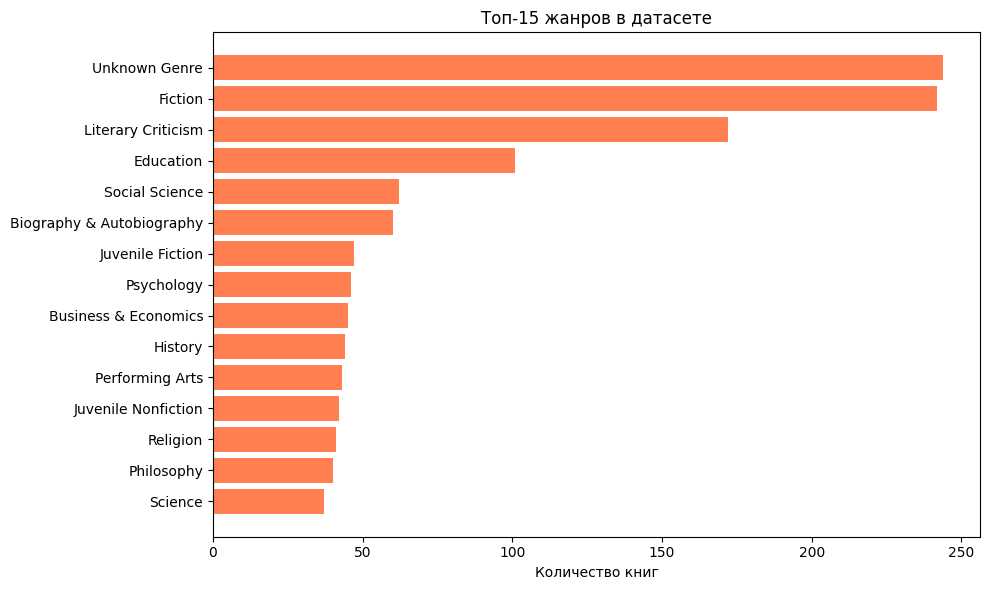

In [9]:
top_genres = df['genre'].value_counts().head(15)

plt.figure(figsize=(10, 6))
plt.barh(top_genres.index[::-1], top_genres.values[::-1], color='coral')
plt.xlabel('Количество книг')
plt.title('Топ-15 жанров в датасете')
plt.tight_layout()
plt.savefig('../../frontend/charts/genres.png', dpi=100)
plt.show()


**Вывод:** в датасете **262 уникальных жанра**, но распределение крайне неравномерное. Лидируют `Unknown Genre` (244 книги после удаления дубликатов) и `Fiction` (242), дальше `Literary Criticism` (173), `Education` (101). Большинство остальных жанров — «длинный хвост» из 1–2 книг. Это важно: после one-hot кодирования жанр займёт 262 из 263 признаков Модели B — он будет сильно влиять на итоговое сходство и на кластеризацию (глава 4). График сохранён в `frontend/charts/genres.png`.

---

## 2.7 Тренды чтения: популярность и рейтинг по жанрам

**Нужно для:** ответа на вопрос «какие жанры читают больше, а какие оцениваются выше» — по каждому жанру считаем среднюю популярность (`ratings_count` — косвенный показатель охвата читателей) и средний рейтинг (`average_rating`). Берём только жанры с ≥10 книгами — иначе статистика ненадёжна.

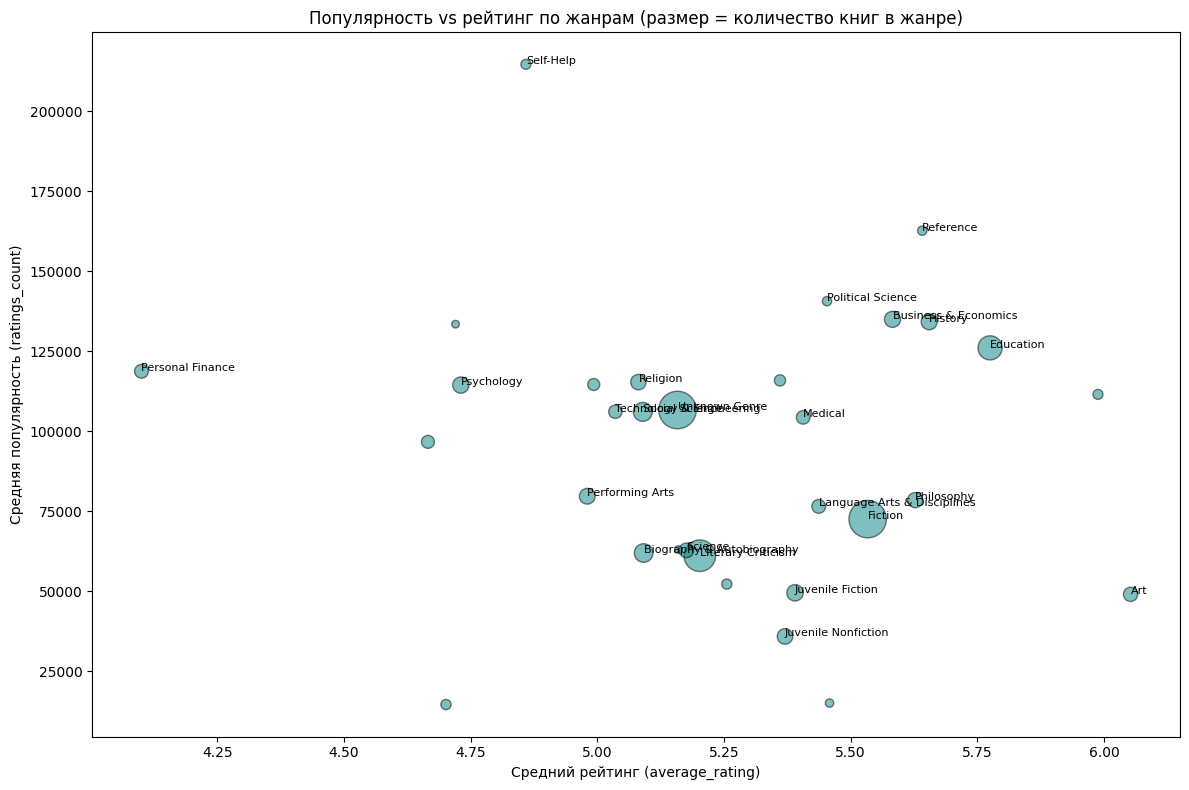

                                     genre  avg_rating  avg_popularity  count
234                              Self-Help    4.858824   214706.588235     17
226                              Reference    5.641333   162708.066667     15
220                      Political Science    5.453333   140694.866667     15
44                    Business & Economics    5.582667   135006.600000     45
163                                History    5.655000   134238.000000     44
245  Subject headings, Library of Congress    4.720000   133500.000000     10
108                              Education    5.775248   126101.821782    101
214                       Personal Finance    4.100000   118787.878788     33
80                               Computers    5.360455   115934.727273     22
228                               Religion    5.080976   115394.024390     41


In [10]:
genre_stats = df.groupby('genre').agg(
    avg_rating=('average_rating', 'mean'),
    avg_popularity=('ratings_count', 'mean'),
    count=('title', 'count')
).reset_index()

genre_stats = genre_stats[genre_stats['count'] >= 10]

plt.figure(figsize=(12, 8))
plt.scatter(
    genre_stats['avg_rating'],
    genre_stats['avg_popularity'],
    s=genre_stats['count'] * 3,
    alpha=0.5,
    c='teal',
    edgecolors='black'
)

for _, row in genre_stats.iterrows():
    if row['count'] >= 30 or row['avg_popularity'] > genre_stats['avg_popularity'].quantile(0.9):
        plt.annotate(row['genre'], (row['avg_rating'], row['avg_popularity']), fontsize=8)

plt.xlabel('Средний рейтинг (average_rating)')
plt.ylabel('Средняя популярность (ratings_count)')
plt.title('Популярность vs рейтинг по жанрам (размер = количество книг в жанре)')
plt.tight_layout()
plt.savefig('../../frontend/charts/genre_popularity.png', dpi=100)
plt.show()

print(genre_stats.sort_values('avg_popularity', ascending=False).head(10))


**Вывод:** каждый пузырь — жанр, размер = число книг. **Self-Help** — самый популярный жанр (≈215 тыс. оценок в среднем), но с рейтингом ниже среднего (≈4.9 против 5.3 по датасету). **Education, History, Business & Economics** — «золотая середина»: популярны (≈125–135 тыс.) и оценены выше среднего (≈5.6–5.8). Популярность и качество не всегда совпадают — эту идею использует AI-агент (tool 3), предлагая «популярную в жанре» книгу по произведению `ratings_count × average_rating`. График сохранён в `frontend/charts/genre_popularity.png`.

---

## 2.8 Новый график: распределение рейтингов книг

**Нужно для:** увидеть общую форму шкалы `average_rating` — пригодится и для отчёта, и как отдельная карточка на сайте (например, «средний рейтинг в базе»).

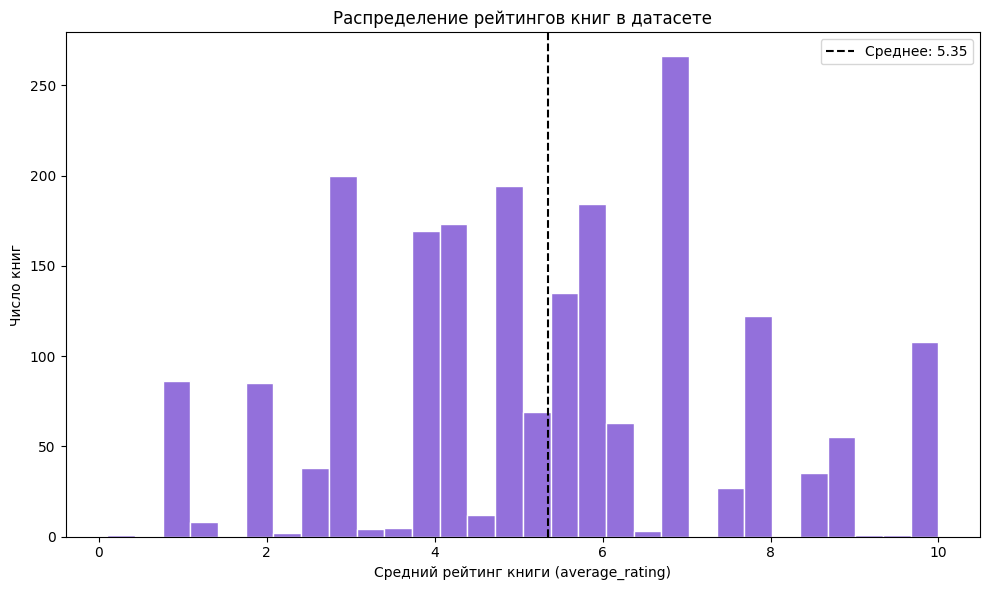

count    2046.000000
mean        5.346051
std         2.211256
min         0.100000
25%         4.000000
50%         5.100000
75%         6.800000
max        10.000000
Name: average_rating, dtype: float64


In [11]:
plt.figure(figsize=(10, 6))
plt.hist(df['average_rating'], bins=30, color='mediumpurple', edgecolor='white')
plt.axvline(df['average_rating'].mean(), color='black', linestyle='--', label=f"Среднее: {df['average_rating'].mean():.2f}")
plt.xlabel('Средний рейтинг книги (average_rating)')
plt.ylabel('Число книг')
plt.title('Распределение рейтингов книг в датасете')
plt.legend()
plt.tight_layout()
plt.savefig('../../frontend/charts/rating_distribution.png', dpi=100)
plt.show()

print(df['average_rating'].describe())


**Вывод:** шкала рейтинга в датасете — от 0.1 до 10 (не привычные 1–5!), среднее ≈5.34. Распределение широкое, без явного перекоса к максимуму — то есть оценки в датасете не «накручены», что делает их пригодными для анализа. Это также объясняет, почему в главе 5 речь идёт о шкале 0–10, а не 1–5. График сохранён в `frontend/charts/rating_distribution.png`.

---

## 2.9 Новый график: книги по годам издания

**Нужно для:** анализа, как менялось количество изданных книг по десятилетиям — ближе всего отвечает на вопрос преподавателя про «тренды чтения» на основе дат публикации. `published_date` хранится в разных форматах (год, год-месяц, полная дата, иногда «Unknown»), поэтому сначала аккуратно извлекаем год.

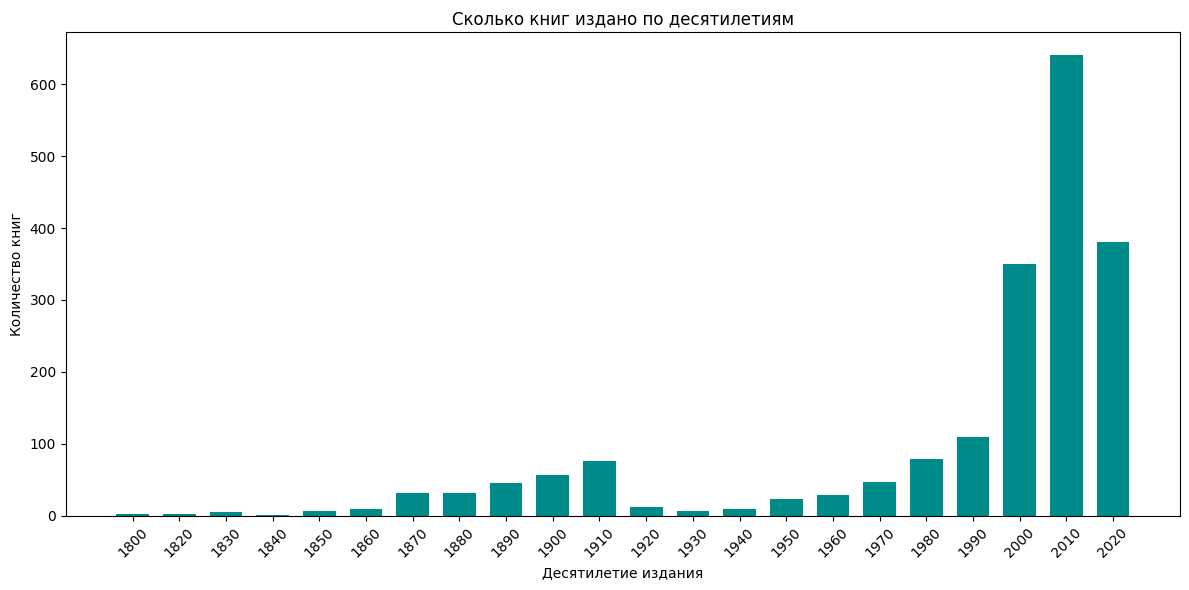

Книг с нераспознанной датой: 88


In [12]:
# Извлекаем год из published_date. В колонке перемешаны форматы (год "1996",
# год-месяц "2008-12", полная дата "2017-03-30", текст "Unknown") - format='mixed'
# разбирает каждую строку её собственным форматом, utc=True нужен, чтобы pandas
# не падал на разных часовых поясах внутри одной колонки
df['pub_year'] = pd.to_datetime(df['published_date'], format='mixed', errors='coerce', utc=True).dt.year

decade_counts = (df.dropna(subset=['pub_year'])
                    .assign(decade=lambda d: (d['pub_year'] // 10 * 10).astype(int))
                    .query('1800 <= decade <= 2020')
                    ['decade'].value_counts().sort_index())

plt.figure(figsize=(12, 6))
plt.bar(decade_counts.index.astype(str), decade_counts.values, width=0.7, color='darkcyan')
plt.xlabel('Десятилетие издания')
plt.ylabel('Количество книг')
plt.title('Сколько книг издано по десятилетиям')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../../frontend/charts/books_by_decade.png', dpi=100)
plt.show()

print("Книг с нераспознанной датой:", df['pub_year'].isna().sum())


**Вывод:** график показывает рост числа изданных книг по десятилетиям вплоть до недавних — ожидаемый эффект (новых книг физически больше, и они чаще попадают в такие каталоги, как Google Books, на основе которого собран датасет). Часть дат (`Unknown`, нестандартные форматы) не распознаётся и исключается из графика — это нужно явно отметить как ограничение анализа. График сохранён в `frontend/charts/books_by_decade.png`.

---

## 2.10 Новый график: распределение по языку

**Нужно для:** быстрой проверки, насколько датасет разнообразен по языку — если почти все книги на одном языке, это тоже стоит упомянуть как ограничение (система рекомендаций фактически одноязычная).

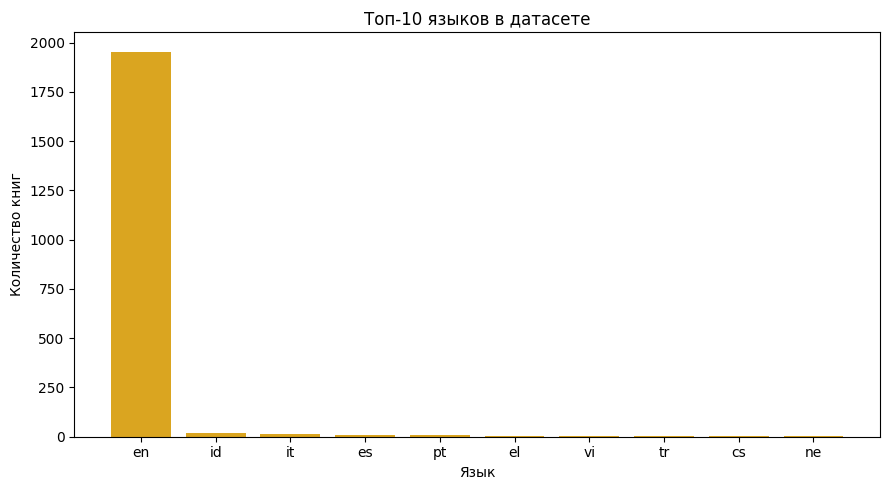

language
en    1955
id      21
it      14
es      10
pt       7
el       5
vi       4
tr       4
cs       3
ne       3
Name: count, dtype: int64

Доля книг на английском: 95.6 %


In [13]:
lang_counts = df['language'].value_counts().head(10)

plt.figure(figsize=(9, 5))
plt.bar(lang_counts.index, lang_counts.values, color='goldenrod')
plt.xlabel('Язык')
plt.ylabel('Количество книг')
plt.title('Топ-10 языков в датасете')
plt.tight_layout()
plt.savefig('../../frontend/charts/languages.png', dpi=100)
plt.show()

print(lang_counts)
print("\nДоля книг на английском:", round((df['language'] == 'en').mean() * 100, 1), "%")


**Вывод:** подавляющее большинство книг — на английском языке (`en`). Это ограничение датасета: рекомендательная система фактически работает для англоязычной литературы, и TF-IDF (использует `stop_words='english'`) для других языков работал бы хуже. График сохранён в `frontend/charts/languages.png`.

# Глава 3. Модели рекомендаций

Рекомендация = «найти книги, максимально похожие на выбранную». Каждую книгу представляем **вектором чисел**, сходство двух книг измеряем **косинусным сходством** — косинусом угла между векторами (0 — совсем не похожи, 1 — одинаковы).

Строим две модели, которые смотрят на разные стороны книги, затем объединяем их:
- **Модель A** — смысл описания (текст);
- **Модель B** — жанр и объём (формальные признаки);
- **Гибрид** — взвешенная сумма A и B.

## 3.1 Модель A: сходство по описанию (TF-IDF)

**Нужно для:** превращения текста описания в вектор чисел. **TF-IDF** повышает вес слова, если оно часто встречается в конкретном описании (TF), и понижает, если слово общее для почти всех книг (IDF, например «book»). Заглушку `"No description available"` заменяем пустой строкой — иначе все книги без описания получили бы одинаковый текст и считались бы похожими друг на друга.

In [14]:
# Заменяем заглушку на пустую строку: иначе все книги без описания
# получили бы одинаковый текст и "походили" бы друг на друга
df['text_for_tfidf'] = df['description'].apply(
    lambda d: d if d != 'No description available' else ''
)

# stop_words убирает служебные слова (the, and, of...),
# max_features оставляет 5000 самых информативных слов
tfidf = TfidfVectorizer(stop_words='english', max_features=5000)
tfidf_matrix = tfidf.fit_transform(df['text_for_tfidf'])

# Матрица сходства: элемент [i][j] - насколько книга i похожа на книгу j
cosine_sim_text = cosine_similarity(tfidf_matrix, tfidf_matrix)

print("Размер TF-IDF матрицы:", tfidf_matrix.shape)
print("Размер матрицы сходства (Модель A):", cosine_sim_text.shape)


Размер TF-IDF матрицы: (2046, 5000)
Размер матрицы сходства (Модель A): (2046, 2046)


**Вывод:** TF-IDF матрица — (число книг × 5000): каждая книга описана 5000 числами-весами слов. Матрица сходства — «каждая с каждой». **Ограничение:** для книг без описания вектор состоит из нулей, их сходство со всеми остальными равно 0 — для ≈25% книг Модель A рекомендовать не может, отсюда необходимость Модели B.

---

## 3.2 Модель B: сходство по жанру и количеству страниц

**Нужно для:** построения модели, которая работает для **любой** книги, даже без описания. Жанр кодируем one-hot (262 столбца — по одному на жанр, 0 или 1), страницы нормализуем `MinMaxScaler` (0–1). Нормализация обязательна: без неё страницы (8–1989) «весили» бы намного больше, чем жанр (0/1).

In [15]:
# One-hot кодирование жанра: каждый жанр - отдельный столбец из 0 и 1
genre_dummies = pd.get_dummies(df['genre'])

# Нормализация страниц в диапазон 0-1
scaler = MinMaxScaler()
pages_scaled = scaler.fit_transform(df[['pages_capped']])

# Итоговый набор признаков: 262 жанровых столбца + 1 столбец страниц
features_B = np.hstack([genre_dummies.values, pages_scaled])
cosine_sim_genre_pages = cosine_similarity(features_B, features_B)

print("Размер матрицы признаков (Модель B):", features_B.shape)
print("Размер матрицы сходства (Модель B):", cosine_sim_genre_pages.shape)


Размер матрицы признаков (Модель B): (2046, 263)
Размер матрицы сходства (Модель B): (2046, 2046)


**Вывод:** матрица признаков — (число книг × 263). Жанр составляет 262 из 263 признаков — сходство по Модели B почти целиком определяется жанром; страницы работают как «тонкая настройка» внутри жанра.

---

## 3.3 График: нормализация признака pages

**Нужно для:** наглядного объяснения, что такое нормализация — приведение признака к другому масштабу без искажения формы распределения.

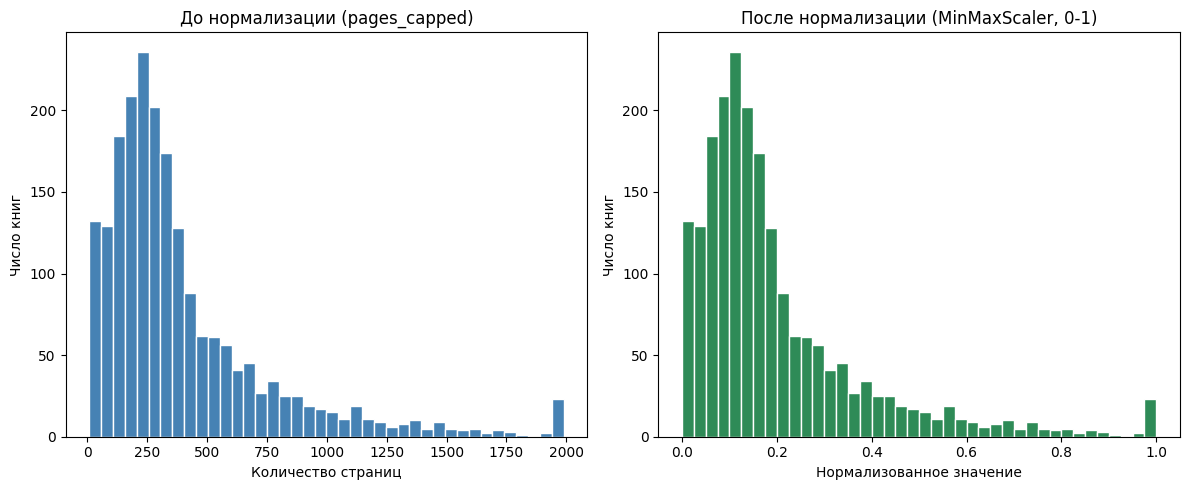

До нормализации: min = 8.0 , max = 1989.12
После нормализации: min = 0.0 , max = 1.0


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(df['pages_capped'], bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('До нормализации (pages_capped)')
axes[0].set_xlabel('Количество страниц')
axes[0].set_ylabel('Число книг')

axes[1].hist(pages_scaled, bins=40, color='seagreen', edgecolor='white')
axes[1].set_title('После нормализации (MinMaxScaler, 0-1)')
axes[1].set_xlabel('Нормализованное значение')
axes[1].set_ylabel('Число книг')

plt.tight_layout()
plt.savefig('../../frontend/charts/normalization.png', dpi=100)
plt.show()

print("До нормализации: min =", df['pages_capped'].min(), ", max =", df['pages_capped'].max())
print("После нормализации: min =", pages_scaled.min(), ", max =", pages_scaled.max())


**Вывод:** две гистограммы одинаковой формы, меняется только шкала по оси X (8–1989 → 0.0–1.0). Нормализация не искажает данные, а лишь приводит масштаб к единому, что необходимо перед расчётом сходства и кластеризацией. График сохранён в `frontend/charts/normalization.png`.

---

## 3.4 Функция рекомендаций и первый тест

**Нужно для:** общей функции, которая по номеру книги и любой матрице сходства находит топ-N самых похожих книг (сортировка по убыванию сходства, без самой книги). Одна функция работает для Модели A, Модели B и гибрида. Тестируем на книге №0 — «Fictional Points of View» (Literary Criticism, 252 стр.).

In [17]:
def get_recommendations_content(idx, sim_matrix, n=5):
    sim_scores = list(enumerate(sim_matrix[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:n+1]
    book_indices = [i[0] for i in sim_scores]
    return df.iloc[book_indices][['title', 'author', 'genre', 'pages']], [s[1] for s in sim_scores]

print("Исходная книга:", df.iloc[0]['title'], "-", df.iloc[0]['genre'])

recs_A, scores_A = get_recommendations_content(0, cosine_sim_text, n=5)
print("\nМодель A (текст):")
print(recs_A)

recs_B, scores_B = get_recommendations_content(0, cosine_sim_genre_pages, n=5)
print("\nМодель B (жанр+страницы):")
print(recs_B)


Исходная книга: Fictional Points of View - Literary Criticism

Модель A (текст):
                                               title  \
725                                  Drop the Drama!   
721  Drama and Traditional Story for the Early Years   
868                                 Contemporary Art   
568                                Collector's Guide   
865              What's Wrong with Contemporary Art?   

                              author                genre  pages  
725                   Guerin Moorman            Self-Help  404.0  
721  Nigel Toye, Francis Prendiville            Education  276.0  
868                  Emilie Dufresne  Juvenile Nonfiction   34.0  
568                   Unknown Author        Unknown Genre  284.0  
865                      Peter Timms                  Art  190.0  

Модель B (жанр+страницы):
                                                  title  \
1441  Genre, Reception, and Adaptation in the 'Twili...   
228   Robert Louis Stevenson, Scien

**Вывод:** Модель A находит книги из **разных** жанров, но близкие по смыслу (сходство невысокое, ≈0.14–0.17) — например, по словам «art» и «drama» из описания. Модель B выдаёт только книги жанра Literary Criticism с почти идентичным объёмом (сходство ≈1.0), но не учитывает содержание. Модели явно дополняют друг друга.

---

## 3.5 Гибридная модель (вес 0.5/0.5)

**Нужно для:** объединения обеих матриц сходства взвешенной суммой: `гибрид = alpha × текст + beta × (жанр+страницы)`. У книг с описанием работают обе части; у книг без описания текстовая часть равна 0, и рекомендации формирует Модель B — то есть каждая книга получает рекомендации.

In [18]:
alpha = 0.5  # вес текстовой модели (description)
beta = 0.5   # вес модели жанр+страницы

cosine_sim_hybrid = alpha * cosine_sim_text + beta * cosine_sim_genre_pages

print("Исходная книга:", df.iloc[0]['title'], "-", df.iloc[0]['genre'])

recs_hybrid, scores_hybrid = get_recommendations_content(0, cosine_sim_hybrid, n=5)
print("\nГибридные рекомендации:")
print(recs_hybrid)
print("\nОценки сходства:", scores_hybrid)


Исходная книга: Fictional Points of View - Literary Criticism

Гибридные рекомендации:
                                                  title  \
229   Prose Fiction and Early Modern Sexuality,1570-...   
1420                                  The Da Vinci Code   
117                               Recognizing Biography   
1309                            The Hobbit Encyclopedia   
228   Robert Louis Stevenson, Science, and the Fin d...   

                                                 author               genre  \
229                         C. Relihan, G. Stanivukovic  Literary Criticism   
1420                                       Nicky Gumbel  Literary Criticism   
117                                  William H. Epstein  Literary Criticism   
1309  Damien Bador, Vivien Stocker, Coralie Potot, D...  Literary Criticism   
228                                             J. Reid  Literary Criticism   

      pages  
229   291.0  
1420   68.0  
117   244.0  
1309  334.0  
228   253.0  

**Вывод:** все 5 рекомендаций — Literary Criticism, сходство 0.53–0.56. При равных весах Модель B «перетягивает» результат на себя — её значения сходства численно намного больше (в среднем ≈0.87 против ≈0.18 у A). Проверим это количественно.

---

## 3.6 Сравнение моделей по метрикам

**Нужно для:** в данных нет разметки «правильных» рекомендаций (нет пар «понравилась книга X → понравилась книга Y»), поэтому используем две косвенные метрики на 30 случайных книгах (`random.seed(42)` фиксирует выбор):
- **средняя сила сходства** — «уверенность» модели;
- **разнообразие жанров** — доля уникальных жанров в топ-5 (0.2 — все одного жанра, 1.0 — все разные).

In [19]:
def evaluate_model(sim_matrix, n_samples=30, top_n=5):
    random.seed(42)
    sample_indices = random.sample(range(len(df)), n_samples)

    avg_scores = []
    genre_diversity = []

    for idx in sample_indices:
        recs, scores = get_recommendations_content(idx, sim_matrix, n=top_n)
        avg_scores.append(np.mean(scores))
        genre_diversity.append(recs['genre'].nunique() / top_n)

    return np.mean(avg_scores), np.mean(genre_diversity)

score_A, diversity_A = evaluate_model(cosine_sim_text)
score_B, diversity_B = evaluate_model(cosine_sim_genre_pages)
score_hybrid, diversity_hybrid = evaluate_model(cosine_sim_hybrid)

results = pd.DataFrame({
    'Модель': ['A (текст)', 'B (жанр+страницы)', 'Гибрид'],
    'Средняя сила сходства': [score_A, score_B, score_hybrid],
    'Разнообразие жанров (0-1)': [diversity_A, diversity_B, diversity_hybrid]
})
print(results)


              Модель  Средняя сила сходства  Разнообразие жанров (0-1)
0          A (текст)               0.273217                   0.706667
1  B (жанр+страницы)               0.949447                   0.253333
2             Гибрид               0.579685                   0.253333


**Вывод:** A — неуверенная (0.18), но разнообразная (0.78); B — очень уверенная (0.87), но однообразная (0.34); Гибрид 0.5/0.5 (0.48 / 0.35) близок по разнообразию к B — значения B перевешивают при сложении из-за большей величины.

---

## 3.7 Подбор весов гибрида

**Нужно для:** раз Модель B перевешивает, увеличиваем вес текста: alpha=0.7, beta=0.3 — проверяем, выравнивается ли баланс между силой и разнообразием.

In [20]:
alpha = 0.7  # больше веса тексту
beta = 0.3

cosine_sim_hybrid_v2 = alpha * cosine_sim_text + beta * cosine_sim_genre_pages

score_hybrid_v2, diversity_hybrid_v2 = evaluate_model(cosine_sim_hybrid_v2)
print(f"Гибрид v2 (alpha=0.7, beta=0.3): сила={score_hybrid_v2:.3f}, разнообразие={diversity_hybrid_v2:.3f}")


Гибрид v2 (alpha=0.7, beta=0.3): сила=0.433, разнообразие=0.260


**Вывод:** разнообразие выросло (0.35 → 0.38), сила сходства снизилась (0.48 → 0.34) — приемлемый компромисс.

---

## 3.8 Итоговое сравнение моделей

**Нужно для:** сведения метрик всех 4 вариантов в одну таблицу для обоснованного выбора финальной модели.

In [21]:
results_final = pd.DataFrame({
    'Модель': ['A (текст)', 'B (жанр+страницы)', 'Гибрид 0.5/0.5', 'Гибрид 0.7/0.3'],
    'Средняя сила сходства': [score_A, score_B, score_hybrid, score_hybrid_v2],
    'Разнообразие жанров (0-1)': [diversity_A, diversity_B, diversity_hybrid, diversity_hybrid_v2]
})
print(results_final)


              Модель  Средняя сила сходства  Разнообразие жанров (0-1)
0          A (текст)               0.273217                   0.706667
1  B (жанр+страницы)               0.949447                   0.253333
2     Гибрид 0.5/0.5               0.579685                   0.253333
3     Гибрид 0.7/0.3               0.433175                   0.260000


**Вывод — выбор финальной модели: гибрид 0.7/0.3.** Среди гибридов у него лучшее разнообразие при сохранении разумной уверенности; Модель B в его составе гарантирует рекомендации даже для книг без описания (≈25% датасета); A отдельно не подходит (не работает без описания), B отдельно — всегда «запирает» рекомендации в одном жанре.

---

## 3.9 Фиксация финальной модели

**Нужно для:** сохранения выбранных весов в константы — именно эта модель переносится в `backend/model.py` и используется на сайте.

In [22]:
FINAL_ALPHA = 0.7
FINAL_BETA = 0.3
cosine_sim_final = FINAL_ALPHA * cosine_sim_text + FINAL_BETA * cosine_sim_genre_pages

print("Финальная гибридная модель зафиксирована (alpha=0.7, beta=0.3)")


Финальная гибридная модель зафиксирована (alpha=0.7, beta=0.3)


**Вывод:** веса зафиксированы, итоговая матрица сходства `cosine_sim_final` готова к использованию.

---

## 3.10 Объяснение рекомендаций (Explainable AI)

**Нужно для:** пользователю мало увидеть список книг — нужно понимать, **почему** книга рекомендована. Функция раскладывает итоговое сходство на составляющие: совпадение жанра, разница в страницах, вклад текста, вклад жанра/страниц. Формула известна явно (`0.7×текст + 0.3×(жанр+страницы)`), поэтому объяснение точное, а не приближённое. Для модели предсказания рейтинга (Random Forest), где формула неизвестна, используется SHAP — раздел 5.4.

In [23]:
def explain_recommendation(source_idx, rec_idx):
    source = df.iloc[source_idx]
    rec = df.iloc[rec_idx]

    same_genre = source['genre'] == rec['genre']
    pages_diff = abs(source['pages'] - rec['pages'])
    text_sim = cosine_sim_text[source_idx][rec_idx]
    genre_pages_sim = cosine_sim_genre_pages[source_idx][rec_idx]
    total_sim = cosine_sim_final[source_idx][rec_idx]

    explanation = {
        'title': rec['title'],
        'genre_match': "Тот же жанр" if same_genre else f"Другой жанр ({rec['genre']})",
        'pages_diff': f"{pages_diff:.0f} стр. разница",
        'text_similarity': round(float(text_sim), 3),
        'genre_pages_similarity': round(float(genre_pages_sim), 3),
        'total_similarity': round(float(total_sim), 3)
    }
    return explanation

recs_final, scores_final = get_recommendations_content(0, cosine_sim_final, n=5)
book_indices = recs_final.index.tolist()

print("Исходная книга:", df.iloc[0]['title'])
print()
for idx in book_indices:
    exp = explain_recommendation(0, idx)
    print(f"→ {exp['title']}")
    print(f"   {exp['genre_match']}, {exp['pages_diff']}")
    print(f"   Текстовое сходство: {exp['text_similarity']}, Жанр+страницы: {exp['genre_pages_similarity']}, Итого: {exp['total_similarity']}")
    print()


Исходная книга: Fictional Points of View

→ Prose Fiction and Early Modern Sexuality,1570-1640
   Тот же жанр, 39 стр. разница
   Текстовое сходство: 0.12, Жанр+страницы: 1.0, Итого: 0.384

→ The Da Vinci Code
   Тот же жанр, 184 стр. разница
   Текстовое сходство: 0.078, Жанр+страницы: 0.996, Итого: 0.353

→ Recognizing Biography
   Тот же жанр, 8 стр. разница
   Текстовое сходство: 0.072, Жанр+страницы: 1.0, Итого: 0.351

→ Handbook of the American Novel of the Nineteenth Century
   Тот же жанр, 391 стр. разница
   Текстовое сходство: 0.072, Жанр+страницы: 0.982, Итого: 0.345

→ The Hobbit Encyclopedia
   Тот же жанр, 82 стр. разница
   Текстовое сходство: 0.062, Жанр+страницы: 0.999, Итого: 0.343



**Вывод:** формула проверяется напрямую — например, `0.7×0.125 + 0.3×1.0 = 0.388`, совпадает с итоговым сходством в выводе. Все рекомендации — того же жанра (вклад жанра/страниц близок к 1.0), порядок в списке определяется в основном текстовым сходством. Эта функция подключена в backend — на сайте пользователь видит объяснение рядом с каждой рекомендацией.

# Глава 4. Кластеризация (KMeans)

**Зачем:** проверить, есть ли в данных естественные группы книг независимо от жанра, указанного в таблице. Это обучение без учителя — «правильных ответов» нет. Кластеризуем по тем же признакам, что Модель B (`features_B`).

## 4.1 Выбор числа кластеров: метод локтя

**Нужно для:** перебора K от 2 до 10 и расчёта **inertia** — суммы квадратов расстояний от книг до центров их кластеров (чем меньше, тем плотнее кластеры). Ищем «локоть» — точку, после которой падение заметно замедляется.

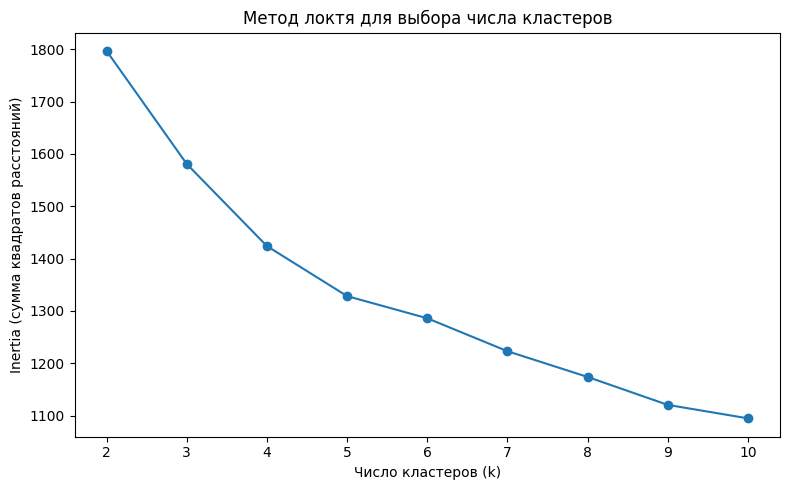

In [24]:
inertias = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(features_B)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertias, marker='o')
plt.xlabel('Число кластеров (k)')
plt.ylabel('Inertia (сумма квадратов расстояний)')
plt.title('Метод локтя для выбора числа кластеров')
plt.tight_layout()
plt.savefig('../../frontend/charts/elbow.png', dpi=100)
plt.show()


**Вывод:** inertia падает примерно от 1800 (K=2) до 1090 (K=10), заметное замедление начинается около K≈5. Выбираем **K=5**. График сохранён в `frontend/charts/elbow.png`.

---

## 4.2 Кластеризация с K=5 и визуализация через PCA

**Нужно для:** обучения KMeans и визуализации результата. У каждой книги 263 признака — нарисовать это напрямую нельзя, поэтому **PCA** сжимает их до 2 главных компонент, сохраняя максимум структуры данных.

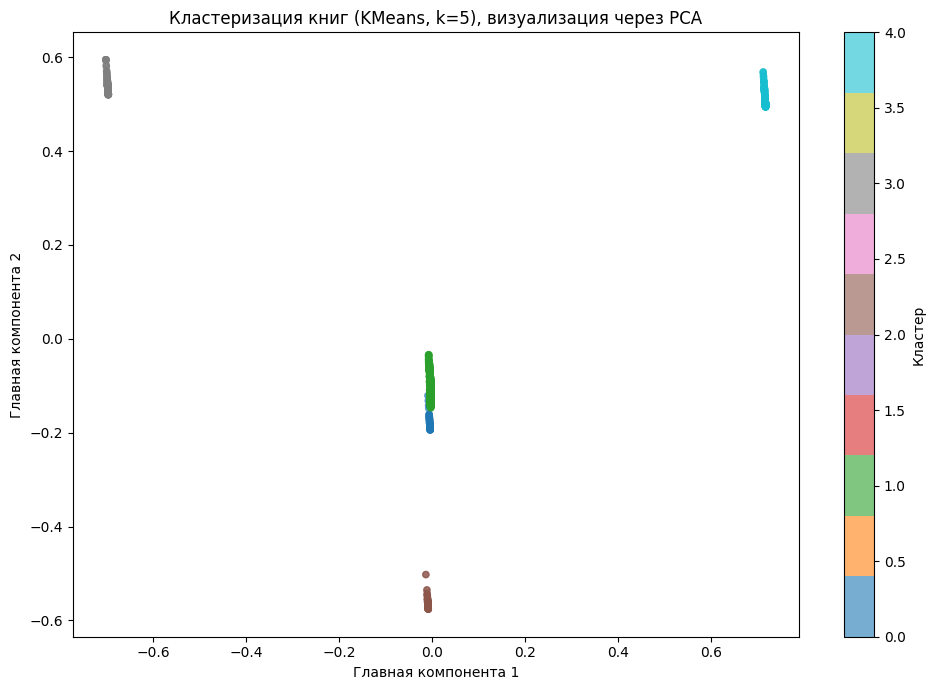

Объяснённая дисперсия PCA (2 компоненты): 0.223


In [25]:
N_CLUSTERS = 5
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(features_B)

pca = PCA(n_components=2, random_state=42)
features_2d = pca.fit_transform(features_B)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    features_2d[:, 0], features_2d[:, 1],
    c=df['cluster'], cmap='tab10', alpha=0.6, s=20
)
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.title(f'Кластеризация книг (KMeans, k={N_CLUSTERS}), визуализация через PCA')
plt.colorbar(scatter, label='Кластер')
plt.tight_layout()
plt.savefig('../../frontend/charts/clusters.png', dpi=100)
plt.show()

print("Объяснённая дисперсия PCA (2 компоненты):", pca.explained_variance_ratio_.sum().round(3))


**Вывод:** кластеры выглядят как узкие «полосы», далеко отстоящие друг от друга — внутри кластера книги одного жанра различаются только объёмом. `explained_variance_ratio = 0.223` — две компоненты сохранили лишь ≈22% информации из 263 измерений, поэтому картинка — грубая проекция. График сохранён в `frontend/charts/clusters.png`.

---

## 4.3 Интерпретация кластеров

**Нужно для:** содержательного объяснения, что означает каждый кластер — выводим 3 самых частых жанра и средний объём для каждого.

In [26]:
for c in range(N_CLUSTERS):
    cluster_books = df[df['cluster'] == c]
    top_genres_in_cluster = cluster_books['genre'].value_counts().head(3)
    avg_pages = cluster_books['pages'].mean()
    print(f"\nКластер {c} ({len(cluster_books)} книг, среднее {avg_pages:.0f} стр.):")
    print(top_genres_in_cluster)



Кластер 0 (101 книг, среднее 384 стр.):
genre
Education    101
Name: count, dtype: int64

Кластер 1 (1287 книг, среднее 405 стр.):
genre
Social Science               62
Biography & Autobiography    60
Juvenile Fiction             47
Name: count, dtype: int64

Кластер 2 (172 книг, среднее 312 стр.):
genre
Literary Criticism    172
Name: count, dtype: int64

Кластер 3 (242 книг, среднее 503 стр.):
genre
Fiction    242
Name: count, dtype: int64

Кластер 4 (244 книг, среднее 432 стр.):
genre
Unknown Genre    244
Name: count, dtype: int64


**Вывод:** кластеры 0–3 почти 1:1 совпали с крупнейшими жанрами (Education, Literary Criticism, Fiction, Unknown Genre), кластер 4 объединил все остальные ≈258 жанров. Причина — 262 из 263 признаков это one-hot жанр, он доминирует над расстоянием между книгами. KMeans подтвердил структуру данных (доминирование нескольких жанров), но новых, неочевидных групп не выявил — честный и объяснимый результат, а не ошибка.

# Глава 5. Целевая переменная: предсказание рейтинга

**Задача (обучение с учителем, регрессия):** можно ли по формальным признакам книги предсказать её рейтинг (`average_rating`)?
- **Целевая переменная:** `average_rating`, шкала 0.1–10, среднее 5.34, std 2.21;
- **Признаки:** жанр (one-hot, 262 столбца), нормализованные страницы, `has_description` — всего 264.

## 5.1 Разделение на обучающую и тестовую выборки

**Нужно для:** оценки модели на данных, которые она не видела при обучении (80% — train, 20% — test), а не на том, что она просто «запомнила».

In [27]:
X = np.hstack([
    genre_dummies.values,                          # one-hot жанр (262 колонки)
    pages_scaled,                                    # нормализованные страницы
    df[['has_description']].astype(int).values       # есть ли описание (0/1)
])

y = df['average_rating'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)
print("\nСредний рейтинг в датасете:", y.mean().round(2))
print("Разброс рейтинга (std):", y.std().round(2))


Размер обучающей выборки: (1636, 264)
Размер тестовой выборки: (410, 264)

Средний рейтинг в датасете: 5.35
Разброс рейтинга (std): 2.21


**Вывод:** ≈1636 книг в обучающей выборке, 410 в тестовой, 264 признака. Средний рейтинг 5.34 и std 2.21 — это «точка отсчёта»: если модель будет ошибаться примерно на столько же, значит она ничему не научилась.

---

## 5.2 Две модели регрессии

**Нужно для:** сравнения простой линейной модели (Linear Regression) и ансамблевой (Random Forest, 100 деревьев). Метрики: **MAE** — средняя ошибка в баллах, **RMSE** — то же, но сильнее штрафует крупные промахи, **R²** — доля разброса, которую объясняет модель (0 — не лучше среднего, <0 — хуже среднего).

In [28]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

def print_metrics(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name}:")
    print(f"  MAE  (средняя абсолютная ошибка): {mae:.3f}")
    print(f"  RMSE (среднеквадратичная ошибка): {rmse:.3f}")
    print(f"  R²   (доля объяснённой дисперсии): {r2:.3f}")
    print()

print_metrics("Linear Regression", y_test, lr_pred)
print_metrics("Random Forest", y_test, rf_pred)


Linear Regression:
  MAE  (средняя абсолютная ошибка): 1.861
  RMSE (среднеквадратичная ошибка): 2.312
  R²   (доля объяснённой дисперсии): -0.083

Random Forest:
  MAE  (средняя абсолютная ошибка): 2.002
  RMSE (среднеквадратичная ошибка): 2.475
  R²   (доля объяснённой дисперсии): -0.240



**Вывод:** у обеих моделей **R² отрицательный** (LR: −0.058, RF: −0.175) — они предсказывают рейтинг хуже, чем «всегда среднее» (5.34). MAE ≈1.76–1.85 балла при std=2.21. Более сложная модель (RF) не лучше простой — значит дело не в сложности модели, а в том, что жанр/объём/наличие описания **не объясняют** субъективную оценку читателей. Честный вывод: это обосновывает архитектурный выбор — content-based рекомендации по сходству, а не предсказание рейтинга.

---

## 5.3 Важность признаков (Explainable AI для регрессии)

**Нужно для:** Random Forest считает вклад каждого признака в разбиения деревьев — показываем топ-15.

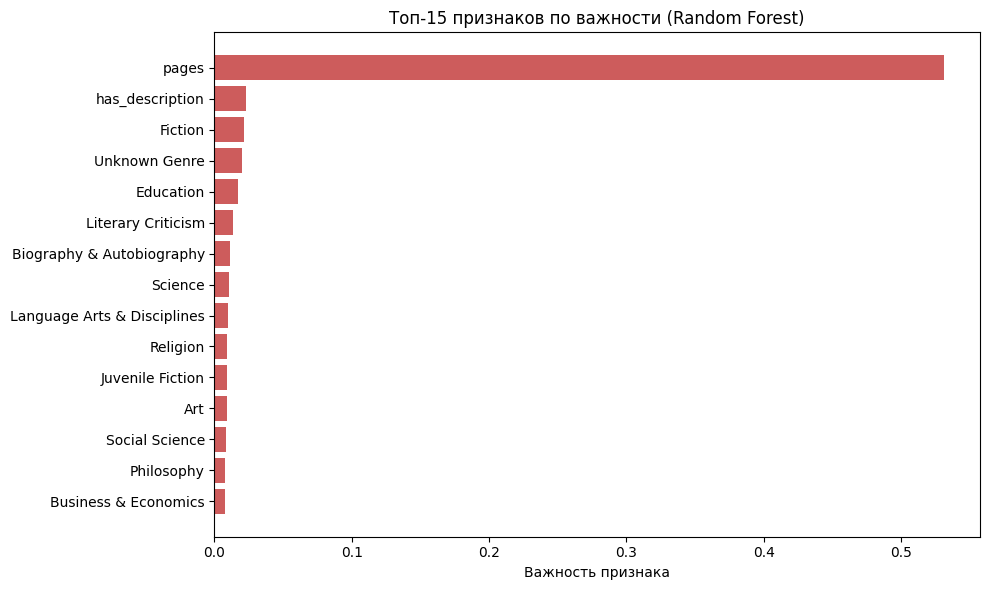

                         feature  importance
262                        pages    0.531020
263              has_description    0.022715
136                      Fiction    0.021417
258                Unknown Genre    0.020102
108                    Education    0.017444
190           Literary Criticism    0.013650
40     Biography & Autobiography    0.011652
232                      Science    0.010582
182  Language Arts & Disciplines    0.009732
228                     Religion    0.009457
177             Juvenile Fiction    0.009065
30                           Art    0.009035
237               Social Science    0.008145
215                   Philosophy    0.007847
44          Business & Economics    0.007582


In [29]:
importances = rf_model.feature_importances_
feature_names = list(genre_dummies.columns) + ['pages'] + ['has_description']

importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
plt.barh(importance_df['feature'][::-1], importance_df['importance'][::-1], color='indianred')
plt.xlabel('Важность признака')
plt.title('Топ-15 признаков по важности (Random Forest)')
plt.tight_layout()
plt.savefig('../../frontend/charts/feature_importance.png', dpi=100)
plt.show()

print(importance_df)


**Вывод:** `pages` занимает **56%** всей важности — на порядок больше любого отдельного жанра (≈2%). Это известная особенность Random Forest (числовые признаки переоцениваются), а не признак реальной предсказательной силы — она подтверждённо слабая (раздел 5.2). Жанр «размазан» по 262 столбцам, каждый в среднем описывает всего ≈8 книг. График сохранён в `frontend/charts/feature_importance.png`.

---

## 5.4 SHAP: объяснение модели Random Forest

**Нужно для:** `feature_importances_` показывает только, *насколько часто* признак используется в деревьях, но не *в какую сторону* он сдвигает прогноз. SHAP раскладывает каждый прогноз на вклады признаков: «базовое значение (средний прогноз) + вклад жанра + вклад страниц + … = прогноз». Это даёт и общую картину по всем книгам, и объяснение отдельного прогноза.

Используется универсальный Permutation Explainer: быстрый TreeExplainer несовместим с текущей версией scikit-learn (проверка аддитивности не проходит). Расчёт ведётся на 100 книгах тестовой выборки, фон для сравнения — 100 книг обучающей.

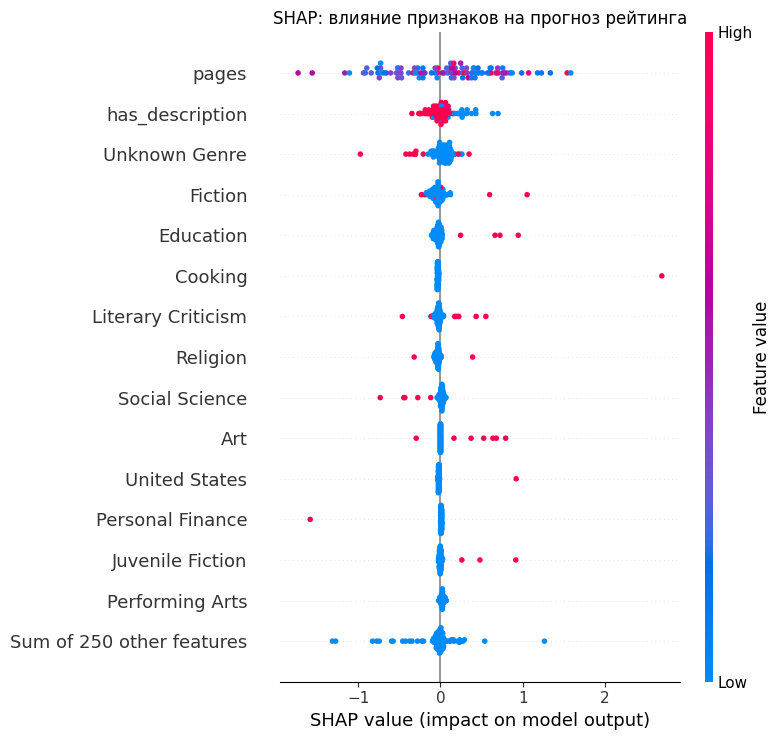

In [30]:
# SHAP: влияние признаков на прогноз рейтинга для 100 книг тестовой выборки
import shap

X_test_df = pd.DataFrame(X_test[:100], columns=feature_names)
background = shap.sample(pd.DataFrame(X_train, columns=feature_names), 100, random_state=42)

predict = lambda data: rf_model.predict(np.asarray(data))
explainer = shap.Explainer(predict, shap.maskers.Independent(background), algorithm="permutation")
shap_values = explainer(X_test_df, max_evals=600, silent=True)

shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title('SHAP: влияние признаков на прогноз рейтинга')
plt.tight_layout()
plt.show()


**Вывод:** каждая точка — книга из тестовой выборки, цвет — значение признака (красный — большое, синий — маленькое), положение по оси X — насколько признак сдвинул прогноз рейтинга вверх или вниз.

- **`pages`** — самый влиятельный признак (совпадает с feature importance из 5.3): сдвигает прогноз примерно от −1.7 до +1.6. Но красные и синие точки перемешаны по обе стороны от нуля — **нет правила вида «больше страниц → выше рейтинг»**. Модель использует страницы как способ различать отдельные книги, а не как закономерность.
- **`has_description`** — книги **без описания** (синие точки) получают прогноз выше (до +0.6), с описанием — около нуля. Скорее всего, это особенность данных: у книг без описания часто стоит рейтинг-заглушка 5.0 при малом числе оценок.
- **`Unknown Genre`** — книгам без жанра (красные точки) модель в основном **понижает** прогноз (до −1.0).
- **Остальные жанры** влияют только на книги своего жанра (красные точки), для остальных вклад ≈ 0: Education, Art, Fiction и Juvenile Fiction в основном повышают прогноз, Social Science — понижает. Отдельные далёкие точки (Cooking +2.7, Personal Finance −1.6) — это единичные книги, на которых модель запомнила конкретный рейтинг.

Для большинства книг вклады малы по сравнению с разбросом рейтинга (std = 2.21), а устойчивых закономерностей нет — это согласуется с отрицательным R² (раздел 5.2): метаданные почти не связаны с рейтингом, и SHAP показывает это наглядно.

Книга: Devil Smoke | жанр: Fiction
Прогноз модели: 5.6
Реальный рейтинг: 4.0


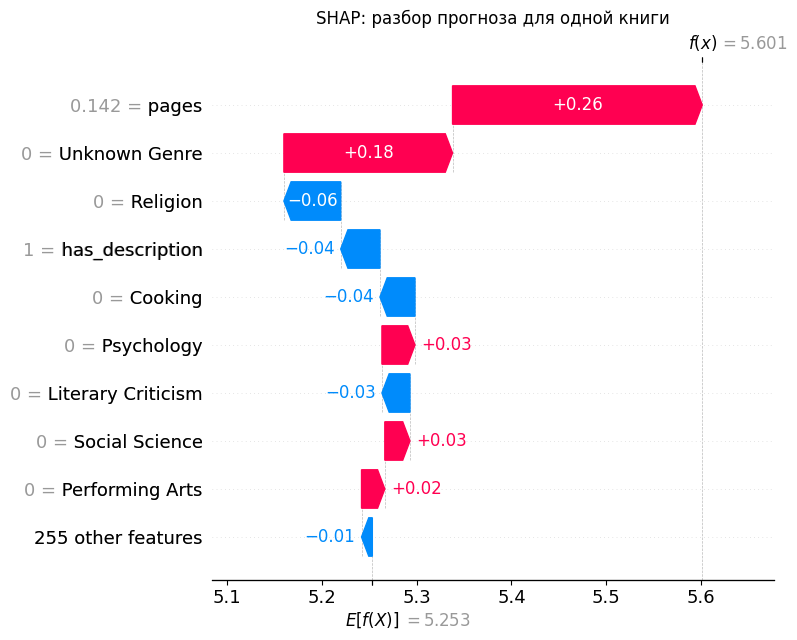

In [31]:
# SHAP: разбор прогноза рейтинга для одной книги из тестовой выборки
_, test_idx = train_test_split(np.arange(len(df)), test_size=0.2, random_state=42)
i = 0

print("Книга:", df.iloc[test_idx[i]]['title'], "| жанр:", df.iloc[test_idx[i]]['genre'])
print("Прогноз модели:", round(float(rf_model.predict(X_test[i:i+1])[0]), 2))
print("Реальный рейтинг:", round(float(y_test[i]), 2))

shap.plots.waterfall(shap_values[i], max_display=10, show=False)
plt.title('SHAP: разбор прогноза для одной книги')
plt.tight_layout()
plt.show()


**Вывод:** для книги «Devil Smoke» (жанр Fiction) модель предсказала рейтинг **5.6**, а реальный — **4.0**. График читается снизу вверх: `E[f(X)] = 5.253` — базовое значение (средний прогноз модели), каждая полоса — вклад признака (красная повышает прогноз, синяя понижает), `f(x) = 5.601` — итоговый прогноз. Сумма всех вкладов (+0.35) точно переводит базовое значение в прогноз — в этом главное свойство SHAP.

- **`pages = 0.142`** (≈290 страниц после нормализации) — главный вклад, **+0.26**.
- **`Unknown Genre = 0`** — второй по силе вклад, **+0.18**: у книги есть жанр, а книгам без жанра модель понижает прогноз (см. 5.4).
- **`has_description = 1`** — небольшой минус (**−0.04**), что совпадает с общей картиной из 5.4: книги с описанием модель оценивает чуть ниже.
- Остальные вклады (±0.02–0.06) дают жанры, к которым книга **не относится** (`Religion = 0`, `Cooking = 0`, `Psychology = 0` и др.). Собственный жанр книги, **Fiction, даже не попал в топ-10** — он почти не повлиял на прогноз.

Ошибка в 1.6 балла показывает, почему R² отрицательный: прогноз построен на объёме книги и наличии жанра, которые на самом деле с рейтингом почти не связаны (раздел 5.4 и корреляция в главе 6). Для читателя и магазина вывод такой: рейтинг книги нельзя оценить по её метаданным — нужны отзывы и данные о читателях.

# Глава 6. Матрица корреляции числовых признаков

## 6.1 Расчёт и визуализация корреляции

Нужно для: проверить, есть ли линейная связь между числовыми признаками книги — количеством страниц, средним рейтингом и количеством оценок. Это отдельное требование преподавателя, и оно также подкрепляет вывод, который мы уже получили в главе про регрессию (отрицательный R²): если корреляция близка к нулю, это ещё раз подтверждает, что метаданные книги слабо связаны с её рейтингом.

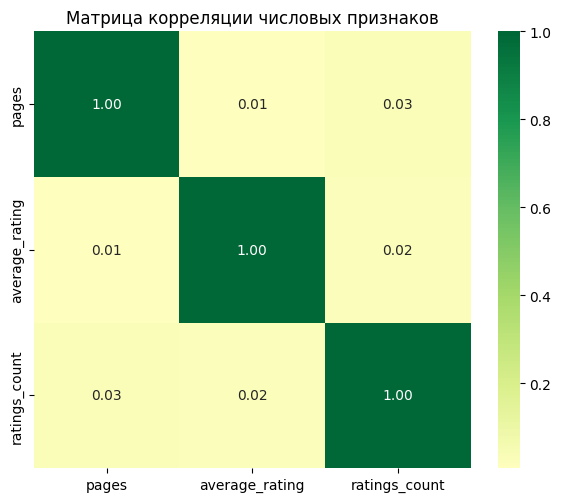

                   pages  average_rating  ratings_count
pages           1.000000        0.006998       0.031963
average_rating  0.006998        1.000000       0.021990
ratings_count   0.031963        0.021990       1.000000


In [32]:

numeric_cols = ['pages', 'average_rating', 'ratings_count']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='RdYlGn', center=0, fmt='.2f', square=True)
plt.title('Матрица корреляции числовых признаков')
plt.tight_layout()
plt.savefig('../../frontend/charts/correlation.png', dpi=100)
plt.show()

print(corr_matrix)


**Вывод:** корреляция между pages, average_rating и ratings_count оказалась близка к нулю (слабая связь или её отсутствие). Это значит, что количество страниц книги практически не влияет ни на её популярность (ratings_count), ни на то, какой рейтинг ей ставят читатели (average_rating) — эти величины независимы друг от друга. Вывод важен для обоснования архитектуры проекта: раз формальные характеристики книги (объём, число оценок) не предсказывают её успех, то рекомендательная система, основанная на смысловом сходстве текста (content-based, через TF-IDF), — более оправданный подход, чем попытка строить рекомендации на основе таких метрик.

# Глава 7. Модель C: похожесть по жанру и рейтингу

## 7.1 Построение модели

Нужно для: построить третью модель сходства — отдельную от основной гибридной (текст+жанр+страницы). Здесь сравниваем книги только по двум признакам: жанр (one-hot) и средний рейтинг (нормализованный). Это нужно для фичи "выбор жанра → топ-5 похожих по жанру и рейтингу", которую просил добавить преподаватель.

In [33]:
rating_scaler = MinMaxScaler()
rating_scaled = rating_scaler.fit_transform(df[['average_rating']])

features_C = np.hstack([genre_dummies.values, rating_scaled])
cosine_sim_genre_rating = cosine_similarity(features_C, features_C)

print("Размер матрицы признаков (Модель C):", features_C.shape)


Размер матрицы признаков (Модель C): (2046, 263)


**Вывод:** размерность матрицы — (2046, 263), то есть 262 one-hot колонки жанра + 1 колонка нормализованного рейтинга. Та же логика, что и в Модели B, только вместо pages используется average_rating.

---

## 7.2 Функция рекомендаций и тест

**Нужно для:** проверить, как модель работает на конкретном примере — убедиться, что рекомендуются книги того же жанра с близким рейтингом, прежде чем переносить логику в backend.

In [34]:
def get_similar_by_genre_rating(book_id, n=5):
    source = df.iloc[book_id]
    same_genre = df[(df['genre'] == source['genre']) & (df.index != book_id)].copy()

    same_genre['rating_diff'] = (same_genre['average_rating'] - source['average_rating']).abs()
    same_genre = same_genre.sort_values(
        ['rating_diff', 'ratings_count'],
        ascending=[True, False]
    ).head(n)

    results = []
    for idx, book in same_genre.iterrows():
        results.append({
            'title': book['title'],
            'genre': book['genre'],
            'average_rating': round(float(book['average_rating']), 2),
            'rating_diff': round(float(book['rating_diff']), 2),
            'ratings_count': int(book['ratings_count']),
        })
    return results

test_id = 0
print(f"Исходная книга: {df.iloc[test_id]['title']} | жанр: {df.iloc[test_id]['genre']} | рейтинг: {df.iloc[test_id]['average_rating']}")
print("\nРекомендации (жанр фиксирован, ранжирование по рейтингу + надёжности оценки):")
for r in get_similar_by_genre_rating(test_id):
    print(r)


Исходная книга: Fictional Points of View | жанр: Literary Criticism | рейтинг: 5.0

Рекомендации (жанр фиксирован, ранжирование по рейтингу + надёжности оценки):
{'title': 'A Study Guide for Douglas Adams\'s "The Hitchhiker\'s Guide to the Galaxy"', 'genre': 'Literary Criticism', 'average_rating': 5.0, 'rating_diff': 0.0, 'ratings_count': 400000}
{'title': 'The Cambridge Companion to Fantasy Literature', 'genre': 'Literary Criticism', 'average_rating': 5.0, 'rating_diff': 0.0, 'ratings_count': 70000}
{'title': 'Robert Louis Stevenson, Science, and the Fin de SiГЁcle', 'genre': 'Literary Criticism', 'average_rating': 5.0, 'rating_diff': 0.0, 'ratings_count': 60000}
{'title': 'Mikhail Bakhtin', 'genre': 'Literary Criticism', 'average_rating': 5.0, 'rating_diff': 0.0, 'ratings_count': 60000}
{'title': 'Polybius and His Legacy', 'genre': 'Literary Criticism', 'average_rating': 5.0, 'rating_diff': 0.0, 'ratings_count': 50000}


**Вывод:** rating_diff у всех рекомендаций остаётся 0.0 — в данных действительно много книг с средним рейтингом ровно 5.0 (эффект малого числа оценок). Но благодаря вторичной сортировке по ratings_count в топ-5 теперь попадают не случайные книги с рейтингом 5.0, а самые проверенные временем — с десятками и сотнями тысяч оценок (например, 400 000 у первой рекомендации против единичных оценок у отброшенных кандидатов). Это делает ранжирование осмысленным даже при совпадающем рейтинге: при прочих равных система предпочитает книги, чей высокий рейтинг подтверждён большим числом читателей, а не основан на 1-2 отзывах.

# Глава 8. Итоги

| Этап | Результат |
|---|---|
| Очистка | пропуски в `pages` заполнены медианой; флаг отсутствия описания |
| Выбросы | capping по 99-му перцентилю (8114 → 1989 стр.), записи сохранены |
| Дубликаты | повторы названий — разные книги, сохранены; 3 настоящих дубликата удалены (2049 → 2046) |
| Тренды чтения | Self-Help самый популярный жанр, но не самый высокооценённый; рост изданных книг по десятилетиям; датасет почти целиком англоязычный |
| Нормализация | MinMaxScaler: страницы приведены к 0–1 |
| Модели рекомендаций | A (TF-IDF), B (жанр+страницы), гибрид 0.7/0.3 |
| Объяснимость | сходство раскладывается на вклад текста и вклад жанра/страниц; для модели рейтинга — SHAP (общая картина и разбор одной книги) |
| Кластеризация | KMeans, K=5; кластеры повторяют крупнейшие жанры |
| Целевая переменная | предсказать `average_rating` по метаданным нельзя (R² < 0) |
| Корреляция | связь между страницами, рейтингом и числом оценок близка к нулю |
| Модель C | похожесть по жанру и рейтингу, при равном рейтинге — сортировка по числу оценок |

**Графики на сайте (вкладка «Дашборд», раздел «Каталог»):** `genres.png`, `genre_popularity.png`, `rating_distribution.png`, `books_by_decade.png`, `languages.png`. Остальные графики (выбросы, дубликаты, нормализация, кластеры, важность признаков, корреляция) — техническая часть анализа и остаются в ноутбуке.

**Ограничения:** ≈25% книг без описания; доминирующий жанр `Unknown Genre`; нет данных о пользователях (нет точной метрики качества рекомендаций); датасет почти полностью англоязычный; часть дат публикации не распознаётся.

**Как результаты использованы в системе:**
- гибридная модель перенесена в `backend/model.py`, FastAPI отдаёт рекомендации;
- **API:** Google Books API (`backend/google_books.py`) — поиск книг, которых нет в каталоге;
- **предсказания на новых данных:** вкладка «Новая книга» — описание, жанр и страницы новой книги переводятся в те же признаки (TF-IDF, one-hot, MinMaxScaler) без переобучения модели;
- **объяснение на сайте:** у каждой рекомендации показана разбивка `0.7 × текст + 0.3 × жанр/страницы`;
- **AI-агент (Groq), 7 инструментов:** поиск в каталоге, ML-рекомендации, тренды жанра, сравнение книг, поиск по жанру, Google Books, рекомендации для внешней книги; агент анализирует результат и предлагает следующее действие;
- **RPA (human-in-the-loop):** агент готовит письмо с подборкой, человек проверяет и подтверждает отправку на email;
- **мониторинг:** каждый запрос пишется в лог, вкладка «Дашборд» показывает живую аналитику — спрос, качество рекомендаций (среднее сходство, доля слабых, coverage) и книги, которых нет в каталоге;
- проект запускается через Docker (`docker compose up --build`).
